# Action Detection in Video — Preprocessing Pipeline (UCF-101)
المطلوب في الـ notebook ده:
1. **Temporal sampling**: سحب عدد ثابت من الفريمز (**≥ 25**، الافتراضي 32) من كل فيديو.
2. **Optical flow generation**: حساب الـ flow وحفظه (flow_x / flow_y كصور + صورة ملوّنة للعرض).
3. **Action localization**: الـ Bounding Box بيتعمل على **منطقة الحركة (الأكشن)** مش على الشخص.
4. **Data augmentation**: على الـ clip كله (RGB + flow + box) بنفس الـ parameters.
5. Visualization + batch processing + manifest.

In [1]:
import os, glob, json, random, shutil, zlib
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
print('OpenCV', cv2.__version__)

OpenCV 5.0.0


## 1) ربط Google Drive
شغّل الخلية اللي تحت ووافق على الصلاحيات. بعدها اكتب مسار فولدر الداتا في خلية الإعدادات (`DATA_ROOT`).

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ================== CONFIG ==================
DATA_ROOT = '/content/drive/MyDrive/UCF-101'   # <<< اكتب هنا مسار فولدر الداتا على Drive (الفولدر اللي جواه الكلاسات)، مثال: '/content/drive/MyDrive/UCF-101'
OUT_ROOT  = '/content/processed_ucf101'        # بنحفظ محلي (أسرع) وبعدين نعمل zip على Drive

NUM_FRAMES = 32          # لازم >= 25
IMG_SIZE   = 224
SAMPLING   = 'uniform'   # 'uniform' (للتست) أو 'random' (TSN-style، للتدريب)
FLOW_METHOD = 'dis'      # 'dis' (سريع) أو 'farneback'
FLOW_BOUND  = 20         # حدود تحويل الـ flow لصورة 0-255

CLASSES = None           # None = كل الكلاسات، أو مثلا ['Archery','Biking']
VIDEOS_PER_CLASS = None  # None = كل الفيديوهات (الداتا كاملة)
N_AUG = 0                # 0 = من غير نسخ augmentation محفوظة (وفّر مساحة، اعملها وقت التدريب). 1 أو 2 لو عايز نسخ محفوظة
SAVE_VIS = False         # True = احفظ كمان صور flow_vis و boxed (للعرض بس، بتزوّد الحجم كتير)
DRIVE_OUT = '/content/drive/MyDrive/UCF101_processed'   # هنا بيتحفظ zip لكل كلاس
SEED = 42

assert NUM_FRAMES >= 25, 'عدد الفريمز لازم يبقى 25 أو أكتر'
random.seed(SEED); np.random.seed(SEED)
os.makedirs(OUT_ROOT, exist_ok=True)

In [4]:
assert DATA_ROOT.strip(), 'اكتب مسار الداتا في DATA_ROOT (خلية الإعدادات) الأول'
assert os.path.isdir(DATA_ROOT), f'المسار مش موجود: {DATA_ROOT}'
all_videos = sorted(glob.glob(os.path.join(DATA_ROOT, '**', '*.avi'), recursive=True))
print('Total videos found:', len(all_videos))

def class_of(path):
    return os.path.basename(path).split('_')[1]      # v_ApplyEyeMakeup_g01_c01.avi -> ApplyEyeMakeup

by_class = {}
for p in all_videos:
    by_class.setdefault(class_of(p), []).append(p)
print('Classes:', len(by_class))

selected = []
for c in sorted(by_class):
    if CLASSES and c not in CLASSES:
        continue
    vids = by_class[c]
    if VIDEOS_PER_CLASS:
        step = max(1, len(vids) // VIDEOS_PER_CLASS)   # توزيع على مجموعات مختلفة (g01..g25)
        vids = vids[::step][:VIDEOS_PER_CLASS]
    selected += vids
print('Selected videos:', len(selected))
assert len(all_videos) > 0, 'مفيش ملفات .avi في المسار ده، راجع DATA_ROOT'

Total videos found: 13320
Classes: 101
Selected videos: 13320


## 2) Temporal sampling + Optical flow

In [5]:
def read_video(path):
    cap = cv2.VideoCapture(path)
    frames = []
    while True:
        ok, f = cap.read()
        if not ok:
            break
        frames.append(f)          # BGR
    cap.release()
    return frames

def sample_indices(n_total, num=NUM_FRAMES, mode=SAMPLING, rng=None):
    # لو الفيديو أقصر من num بنكرر فريمات (linspace بيعمل ده تلقائيا)
    if mode == 'uniform' or n_total < num:
        idx = np.linspace(0, n_total - 1, num).round().astype(int)
    else:   # random داخل كل segment
        rng = rng or np.random.default_rng()
        seg = np.linspace(0, n_total, num + 1)
        idx = [int(rng.integers(int(a), max(int(a) + 1, int(b)))) for a, b in zip(seg[:-1], seg[1:])]
        idx = np.array(sorted(idx))
    return idx

def make_flow_fn():
    if FLOW_METHOD == 'dis':
        dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
        return lambda a, b: dis.calc(a, b, None)
    return lambda a, b: cv2.calcOpticalFlowFarneback(a, b, None, 0.5, 3, 15, 3, 5, 1.2, 0)

def compute_clip(frames, idx):
    # لكل فريم مختار i بنحسب flow بينه وبين i+1 (أو i-1 -> i لو هو آخر فريم)
    n = len(frames)
    flow_fn = make_flow_fn()
    rgb, flows = [], []
    for i in idx:
        i0, i1 = (i, i + 1) if i + 1 < n else (i - 1, i)
        a = cv2.resize(frames[i0], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        b = cv2.resize(frames[i1], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        g0 = cv2.cvtColor(a, cv2.COLOR_BGR2GRAY)
        g1 = cv2.cvtColor(b, cv2.COLOR_BGR2GRAY)
        flows.append(flow_fn(g0, g1).astype(np.float32))
        rgb.append(a if i0 == i else b)
    return rgb, flows

def flow_to_uint8(flow, bound=FLOW_BOUND):
    f = np.clip(flow, -bound, bound)
    return ((f + bound) * (255.0 / (2 * bound))).round().astype(np.uint8)

def flow_to_color(flow):
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsv = np.zeros((*flow.shape[:2], 3), np.uint8)
    hsv[..., 0] = (ang * 180 / np.pi / 2).astype(np.uint8)
    hsv[..., 1] = 255
    hsv[..., 2] = np.clip(mag * 20, 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

## 3) Action localization (Box على الأكشن مش على الشخص)
بنحسب منطقة الحركة من الـ optical flow بعد ما نشيل حركة الكاميرا (بطرح الـ median flow)، وبناخد أكبر مناطق الحركة كـ **action box**، وبعدين نعمل temporal smoothing للـ boxes عشان متهزش بين الفريمات.

> ملحوظة: UCF-101 الأصلية مفيهاش boxes (الـ boxes موجودة بس لـ UCF101-24 subset). فالـ boxes هنا **pseudo-labels** من الحركة، وتقدر تراجعها/تصلحها لاحقًا أو تستبدلها بـ annotations حقيقية.

In [6]:
def motion_box(flow, thr_ratio=0.4):
    H, W = flow.shape[:2]
    f = flow - np.median(flow.reshape(-1, 2), axis=0)          # شيل حركة الكاميرا
    mag = cv2.GaussianBlur(np.linalg.norm(f, axis=2), (9, 9), 0)
    if mag.max() < 0.3:
        return None, 0.0
    mask = (mag > mag.max() * thr_ratio).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return None, 0.0
    areas = [cv2.contourArea(c) for c in cnts]
    amax = max(areas)
    keep = [c for c, a in zip(cnts, areas) if a >= 0.15 * amax]
    x, y, w, h = cv2.boundingRect(np.vstack(keep))
    pad = int(0.05 * max(H, W))
    x1, y1, x2, y2 = max(0, x - pad), max(0, y - pad), min(W, x + w + pad), min(H, y + h + pad)
    score = float(np.clip(mag[y1:y2, x1:x2].mean() / (mag.max() + 1e-6), 0, 1))
    return [x1, y1, x2, y2], score

def action_boxes(flows, win=5):
    H, W = flows[0].shape[:2]
    raw = [motion_box(f) for f in flows]
    boxes = [r[0] for r in raw]
    scores = np.array([r[1] for r in raw], np.float32)
    full = [0, 0, W, H]
    # املا الفريمات اللي مفيهاش حركة (forward fill ثم backward fill)
    last = None
    for i in range(len(boxes)):
        if boxes[i] is None: boxes[i] = last
        else: last = boxes[i]
    last = None
    for i in range(len(boxes) - 1, -1, -1):
        if boxes[i] is None: boxes[i] = last if last is not None else full
        else: last = boxes[i]
    arr = np.array(boxes, np.float32)
    k, pad = np.ones(win) / win, win // 2
    for c in range(4):                                          # temporal smoothing
        arr[:, c] = np.convolve(np.pad(arr[:, c], (pad, pad), mode='edge'), k, mode='valid')
    return arr, scores

def draw_box(img, box, label=None, color=(0, 255, 0)):
    out = img.copy()
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
    if label:
        cv2.putText(out, label, (x1 + 2, max(12, y1 + 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)
    return out

## 4) Data augmentation (بنفس الـ parameters على كل فريمات الـ clip)

In [7]:
def augment_clip(rgb, flows, boxes, rng):
    # random scale-crop + horizontal flip + brightness/contrast. الـ flow والـ boxes بيتظبطوا مع كل تحويل.
    H, W = rgb[0].shape[:2]
    s = rng.uniform(0.7, 1.0)
    w, h = int(W * s), int(H * s)
    x0 = int(rng.integers(0, W - w + 1)); y0 = int(rng.integers(0, H - h + 1))
    flip = rng.random() < 0.5
    alpha, beta = rng.uniform(0.8, 1.2), rng.uniform(-20, 20)
    out_rgb, out_flow = [], []
    for img, fl in zip(rgb, flows):
        im = cv2.resize(img[y0:y0 + h, x0:x0 + w], (W, H))
        f = cv2.resize(fl[y0:y0 + h, x0:x0 + w], (W, H))
        f[..., 0] *= W / w; f[..., 1] *= H / h                  # الـ zoom بيكبّر قيم الحركة
        if flip:
            im = im[:, ::-1]
            f = f[:, ::-1].copy(); f[..., 0] *= -1             # flip أفقي => x-flow بيتعكس
        im = cv2.convertScaleAbs(np.ascontiguousarray(im), alpha=alpha, beta=beta)
        out_rgb.append(im); out_flow.append(np.ascontiguousarray(f))
    b = boxes.copy()
    b[:, [0, 2]] = (b[:, [0, 2]] - x0) * W / w
    b[:, [1, 3]] = (b[:, [1, 3]] - y0) * H / h
    b[:, [0, 2]] = np.clip(b[:, [0, 2]], 0, W); b[:, [1, 3]] = np.clip(b[:, [1, 3]], 0, H)
    if flip:
        b[:, [0, 2]] = W - b[:, [2, 0]]
    bad = ((b[:, 2] - b[:, 0]) < 4) | ((b[:, 3] - b[:, 1]) < 4)
    b[bad] = [0, 0, W, H]
    return out_rgb, out_flow, b, dict(scale=float(s), crop=[x0, y0, w, h], flip=bool(flip), alpha=float(alpha), beta=float(beta))

## 5) الحفظ + معالجة فيديو كامل

In [8]:
def save_sample(out_dir, rgb, flows, boxes, scores, meta):
    subs = ['rgb', 'flow_x', 'flow_y'] + (['flow_vis', 'boxed'] if SAVE_VIS else [])
    for sub in subs:
        os.makedirs(os.path.join(out_dir, sub), exist_ok=True)
    q = [cv2.IMWRITE_JPEG_QUALITY, 95]
    for t, (img, fl, bx) in enumerate(zip(rgb, flows, boxes)):
        nm = f'{t:03d}.jpg'
        enc = flow_to_uint8(fl)
        cv2.imwrite(os.path.join(out_dir, 'rgb', nm), img, q)
        cv2.imwrite(os.path.join(out_dir, 'flow_x', nm), enc[..., 0], q)
        cv2.imwrite(os.path.join(out_dir, 'flow_y', nm), enc[..., 1], q)
        if SAVE_VIS:
            cv2.imwrite(os.path.join(out_dir, 'flow_vis', nm), flow_to_color(fl), q)
            cv2.imwrite(os.path.join(out_dir, 'boxed', nm), draw_box(img, bx, meta['class']), q)
    ann = dict(meta)
    ann.update(num_frames=len(rgb), img_size=IMG_SIZE, boxes_xyxy=np.round(boxes, 1).tolist(),
               motion_scores=np.round(scores, 3).tolist())
    with open(os.path.join(out_dir, 'annotation.json'), 'w') as f:
        json.dump(ann, f)

def process_video(path, out_root=OUT_ROOT, n_aug=N_AUG):
    cls = class_of(path)
    name = os.path.splitext(os.path.basename(path))[0]
    out_dir = os.path.join(out_root, cls, name)
    if os.path.exists(os.path.join(out_dir, 'annotation.json')):
        return out_dir                                           # already done (resume)
    frames = read_video(path)
    n = len(frames)
    if n < 2:
        raise ValueError(f'video too short/unreadable: {path}')
    rng = np.random.default_rng(zlib.crc32(name.encode()) + SEED)
    idx = sample_indices(n, rng=rng)
    rgb, flows = compute_clip(frames, idx)
    boxes, scores = action_boxes(flows)
    base = dict(video=name, **{'class': cls}, source=path, total_frames=n,
                sampled_indices=idx.tolist(), flow_method=FLOW_METHOD, flow_bound=FLOW_BOUND)
    for k in range(n_aug):
        a_rgb, a_flows, a_boxes, params = augment_clip(rgb, flows, boxes, rng)
        save_sample(os.path.join(out_dir, f'aug_{k}'), a_rgb, a_flows, a_boxes, scores,
                    dict(base, augmentation=params))
    save_sample(out_dir, rgb, flows, boxes, scores, dict(base, augmentation=None))
    return out_dir

## 6) تشغيل الداتا كاملة (كلاس كلاس)
- بيعالج كل فيديوهات الكلاس → بيعمل `manifest.csv` للكلاس → بيضغطه zip على Drive → بيمسح النسخة المحلية عشان المساحة.
- لو الـ session اتقطعت: شغّل نفس الخلية تاني، هيتخطى الكلاسات اللي ملفها موجود على Drive.

In [10]:
os.makedirs(DRIVE_OUT, exist_ok=True)
failed = []
todo = [c for c in sorted(by_class) if (CLASSES is None or c in CLASSES)]
print('Classes to process:', len(todo))

for c in tqdm(todo, desc='Classes'):
    zp = os.path.join(DRIVE_OUT, c)
    if os.path.exists(zp + '.zip'):
        continue                                           # الكلاس ده خلص قبل كده
    vids = by_class[c]
    if VIDEOS_PER_CLASS:
        step = max(1, len(vids) // VIDEOS_PER_CLASS)
        vids = vids[::step][:VIDEOS_PER_CLASS]
    rows = []
    for p in tqdm(vids, desc=c, leave=False):
        try:
            d = process_video(p)
            a = json.load(open(os.path.join(d, 'annotation.json')))
            assert a['num_frames'] >= 25
            rows.append(dict(cls=c, video=a['video'], total_frames=a['total_frames'],
                             sampled=a['num_frames'],
                             mean_motion_score=float(np.mean(a['motion_scores']))))
        except Exception as e:
            failed.append((p, str(e)))
    if not os.path.isdir(os.path.join(OUT_ROOT, c)):
        continue
    pd.DataFrame(rows).to_csv(os.path.join(OUT_ROOT, c, 'manifest.csv'), index=False)
    shutil.make_archive(zp, 'zip', os.path.join(OUT_ROOT, c))   # zip للكلاس على Drive
    shutil.rmtree(os.path.join(OUT_ROOT, c))                    # فضّي المساحة المحلية

print('Done. Failed videos:', len(failed))
for p, e in failed[:10]:
    print(' -', os.path.basename(p), e)

Classes to process: 101


Classes:   0%|          | 0/101 [00:00<?, ?it/s]

Punch:   0%|          | 0/160 [00:00<?, ?it/s]

PushUps:   0%|          | 0/102 [00:00<?, ?it/s]

Rafting:   0%|          | 0/111 [00:00<?, ?it/s]

RockClimbingIndoor:   0%|          | 0/144 [00:00<?, ?it/s]

... (24 outputs left out)

WallPushups:   0%|          | 0/130 [00:00<?, ?it/s]

WritingOnBoard:   0%|          | 0/152 [00:00<?, ?it/s]

YoYo:   0%|          | 0/128 [00:00<?, ?it/s]

Done. Failed videos: 0


## 7) تأكد إن كل الكلاسات اتحفظت

In [11]:
zips = sorted(glob.glob(os.path.join(DRIVE_OUT, '*.zip')))
print('Zip files on Drive:', len(zips), '| expected classes:', len(todo))
missing = [c for c in todo if not os.path.exists(os.path.join(DRIVE_OUT, c + '.zip'))]
print('Missing classes:', missing)
print('Total size (GB): %.2f' % (sum(os.path.getsize(z) for z in zips) / 1e9))

Zip files on Drive: 101 | expected classes: 101
Missing classes: []
Total size (GB): 9.33


## 8) (اختياري) تحميل الداتا على جهازك
الأفضل تحمّلها من Drive نفسه (كليك يمين على فولدر `UCF101_processed` ← Download، أو استخدم Drive for Desktop). الخلية دي بتحمّل ملفات الـ zip واحد ورا التاني من المتصفح، ومناسبة بس لو الحجم صغير.

In [12]:
# اختياري: شغّلها بس لو عايز تحمّل من Colab مباشرة
from google.colab import files
for z in sorted(glob.glob(os.path.join(DRIVE_OUT, '*.zip'))):
    files.download(z)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (192 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

v_Archery_g01_c01 | frames: 32


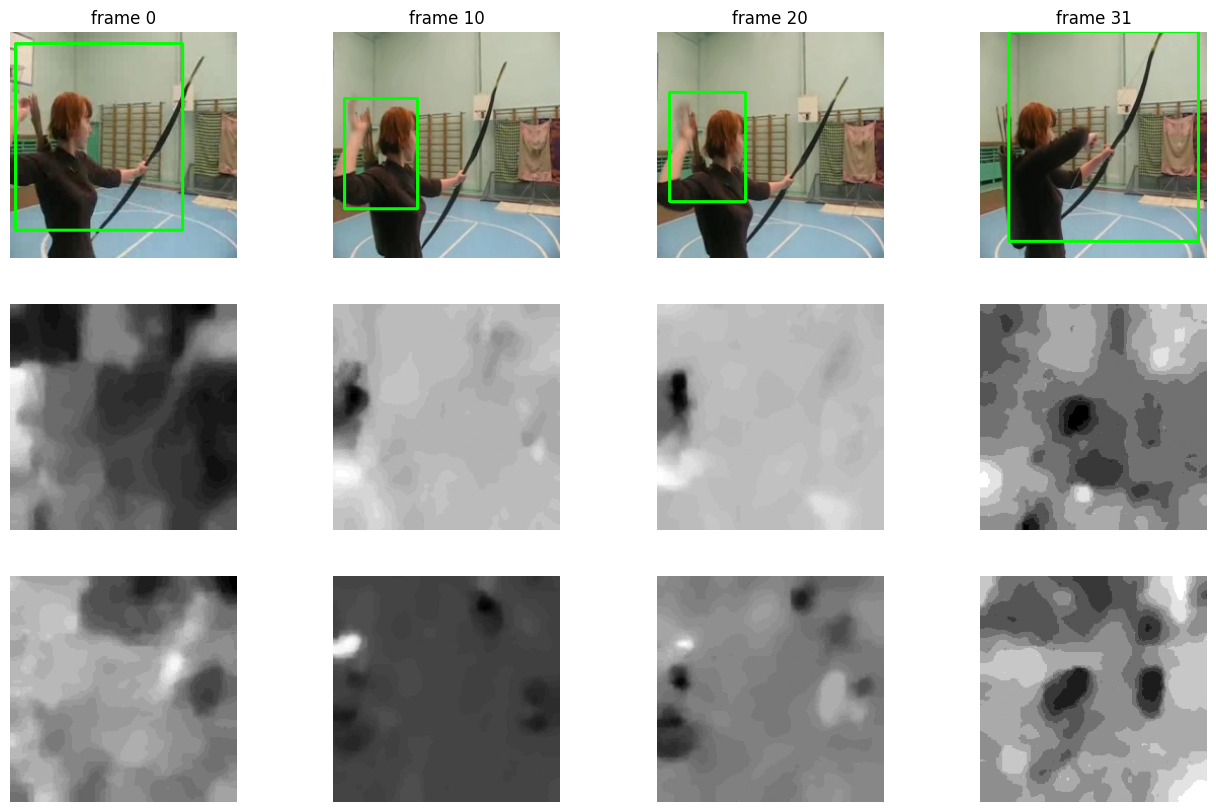

In [14]:
import zipfile
chk = '/content/check'
shutil.rmtree(chk, ignore_errors=True)
z = zipfile.ZipFile(os.path.join(DRIVE_OUT, 'Archery.zip'))
vid = sorted({n.split('/')[0] for n in z.namelist() if '/' in n})[0]
z.extractall(chk, members=[n for n in z.namelist() if n.startswith(vid + '/') and '/aug_' not in n])
d = os.path.join(chk, vid)
ann = json.load(open(os.path.join(d, 'annotation.json')))
print(vid, '| frames:', ann['num_frames'])

fig, axs = plt.subplots(3, 4, figsize=(16, 10))
for j, t in enumerate([0, 10, 20, 31]):
    nm = f'{t:03d}.jpg'
    img = draw_box(cv2.imread(os.path.join(d, 'rgb', nm)), ann['boxes_xyxy'][t])
    axs[0, j].imshow(img[..., ::-1]); axs[0, j].set_title(f'frame {t}')
    axs[1, j].imshow(cv2.imread(os.path.join(d, 'flow_x', nm), 0), cmap='gray')
    axs[2, j].imshow(cv2.imread(os.path.join(d, 'flow_y', nm), 0), cmap='gray')
for a in axs.ravel(): a.axis('off')
plt.show()